<a href="https://colab.research.google.com/github/moksh033/Data-Analytics-and-Visualisation/blob/main/experiment%2010.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from scipy.cluster.hierarchy import dendrogram

In [2]:
students = ['A', 'B', 'C', 'D', 'E', 'F']
marks = [30, 35, 40, 80, 85, 90]

In [3]:
x = np.arange(len(students))
marks_array = np.array(marks)

In [4]:
phases = [
    [[0], [1], [2], [3], [4], [5]],
    [[0, 1], [2], [3], [4], [5]],
    [[0, 1, 2], [3], [4], [5]],
    [[0, 1, 2], [3, 4], [5]],
    [[0, 1, 2], [3, 4, 5]],
    [[0, 1, 2, 3, 4, 5]]
]

In [5]:
titles = [
    "Phase 1: Initial 6 Clusters",
    "Phase 2: Merge A and B",
    "Phase 3: Merge C with AB",
    "Phase 4: Merge D and E",
    "Phase 5: Merge DE with F",
    "Phase 6: Merge ABC and DEF"
]

In [6]:
colors = [
    'blue', 'orange', 'green',
    'red', 'purple', 'brown'
]

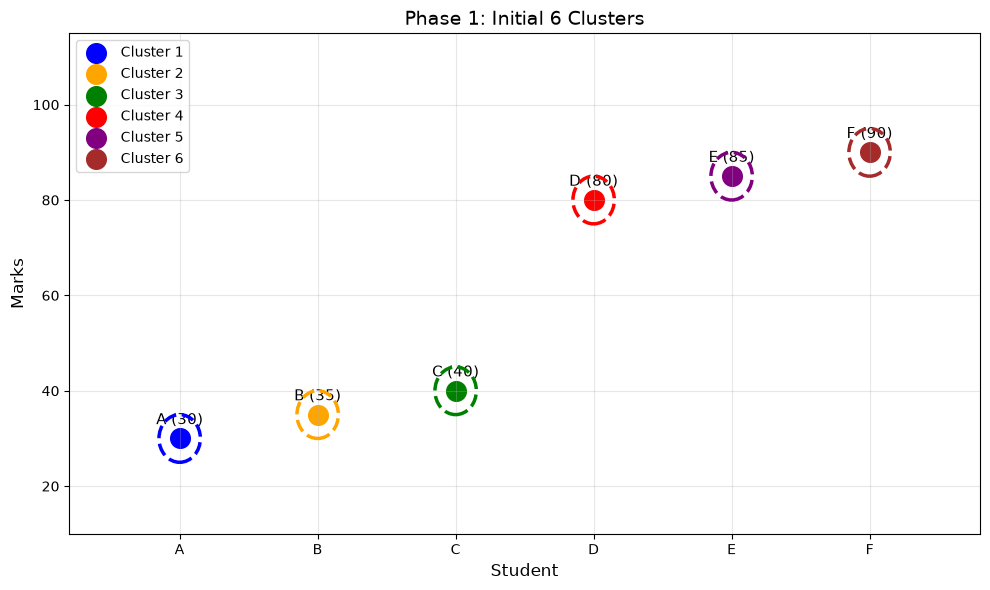

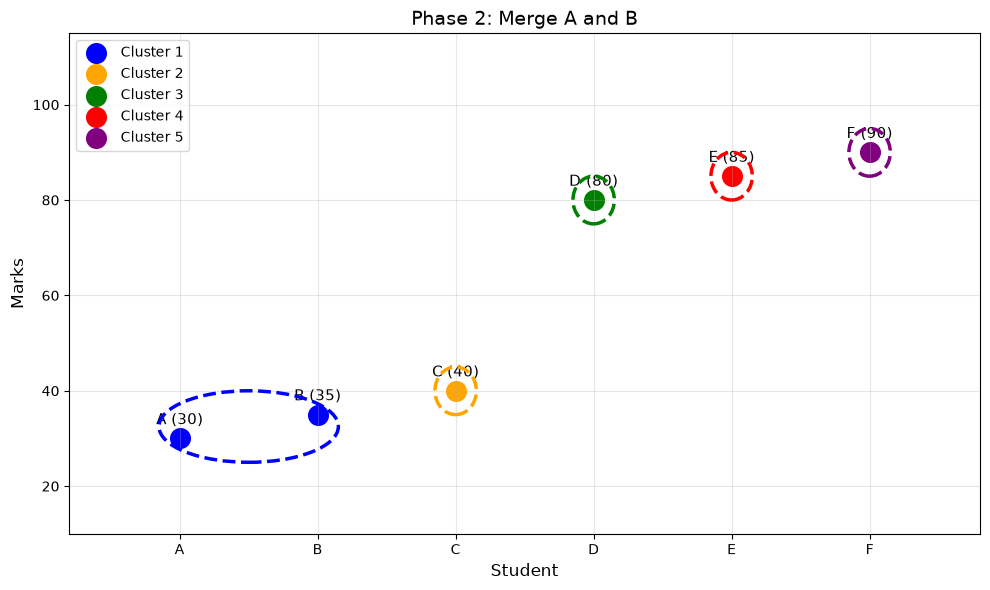

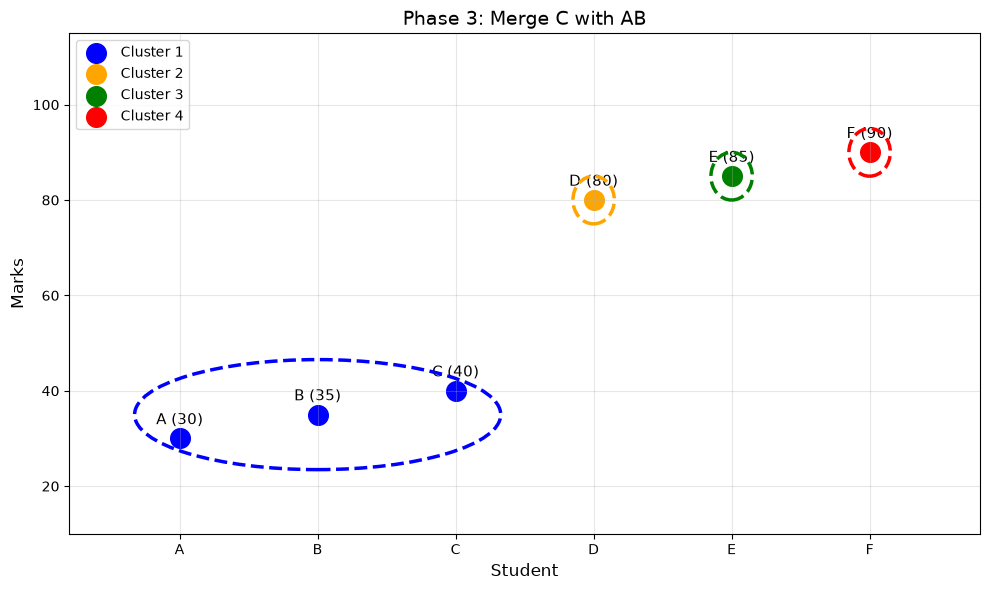

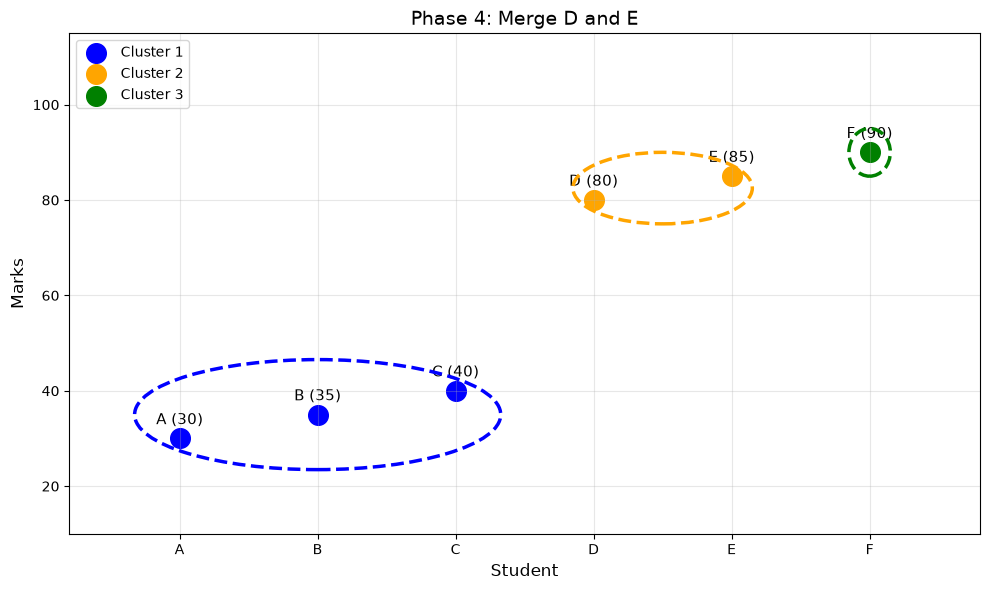

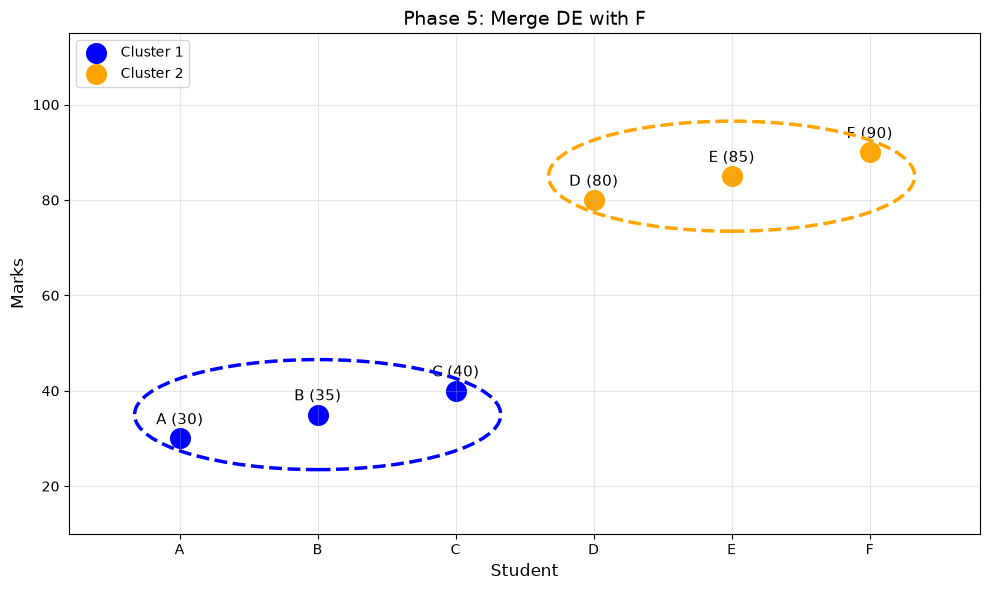

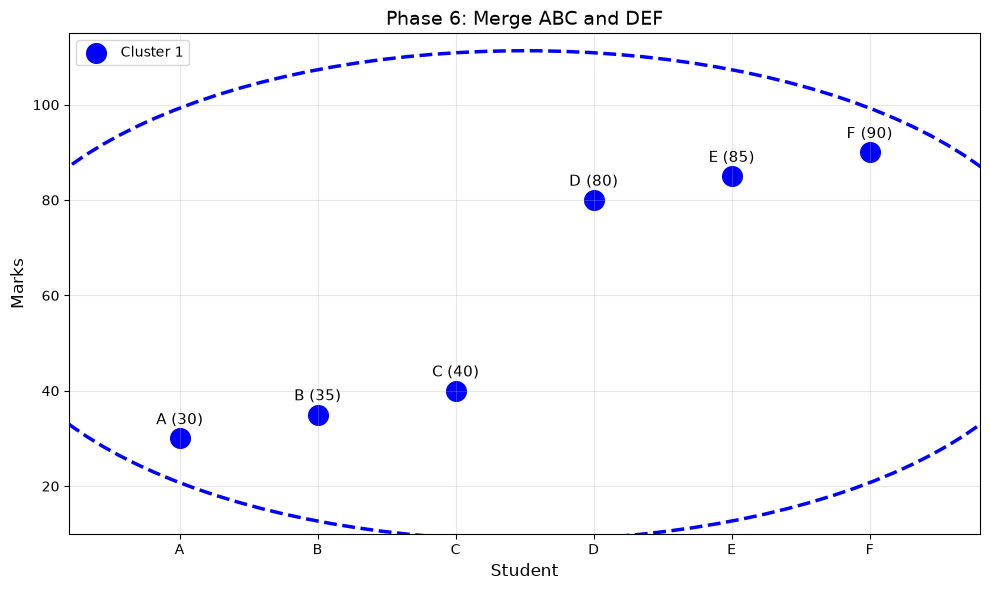

In [7]:
for phase_no, clusters in enumerate(phases):

    fig, ax = plt.subplots(figsize=(10, 6))

    for cluster_no, cluster in enumerate(clusters):

        color = colors[cluster_no]

        cluster_x = x[cluster]
        cluster_y = marks_array[cluster]

        # Plot students

        ax.scatter(
            cluster_x,
            cluster_y,
            color=color,
            s=200,
            label=f'Cluster {cluster_no + 1}'
        )

        # Display student names and marks

        for i in cluster:

            ax.text(
                x[i],
                marks_array[i] + 3,
                f"{students[i]} ({marks[i]})",
                ha='center',
                fontsize=11
            )

        # -----------------------------------
        # Calculate ellipse to cover all points
        # -----------------------------------

        center_x = np.mean(cluster_x)
        center_y = np.mean(cluster_y)

        # Calculate horizontal and vertical radius

        radius_x = max(
            np.max(np.abs(cluster_x - center_x)) + 0.15,
            0.15
        )

        radius_y = max(
            np.max(np.abs(cluster_y - center_y)) + 5,
            5
        )

        # Check the distance of every point from the centre

        distances = np.sqrt(
            ((cluster_x - center_x) / radius_x) ** 2 +
            ((cluster_y - center_y) / radius_y) ** 2
        )

        # Ensure ellipse size can fit all points in cluster

        scale = max(1.0, np.max(distances) * 1.15)

        radius_x *= scale
        radius_y *= scale

        # Draw ellipse

        ellipse = Ellipse(
            (center_x, center_y),
            width=2 * radius_x,
            height=2 * radius_y,
            angle=0,
            facecolor='none',
            edgecolor=color,
            linewidth=2.5,
            linestyle='--',
            zorder=3
        )

        ax.add_patch(ellipse)

    # -----------------------------------

    # Step 4: Improve formatting
    # -----------------------------------

    ax.set_title(titles[phase_no], fontsize=14)

    ax.set_xlabel("Student", fontsize=12)
    ax.set_ylabel("Marks", fontsize=12)

    ax.set_xticks(x)
    ax.set_xticklabels(students)

    ax.set_xlim(-0.8, 5.8)
    ax.set_ylim(10, 115)

    ax.grid(True, alpha=0.3)

    ax.legend(loc='upper left')

    plt.tight_layout()
    plt.show()

In [8]:
Z = np.array([
    [0, 1, 5, 2],    # A + B
    [6, 2, 5, 3],    # AB + C
    [3, 4, 5, 2],    # D + E
    [8, 5, 5, 3],    # DE + F
    [7, 9, 60, 6]    # ABC + DEF
], dtype=np.float64)

{'icoord': [[5.0, 5.0, 15.0, 15.0],
  [10.0, 10.0, 25.0, 25.0],
  [35.0, 35.0, 45.0, 45.0],
  [40.0, 40.0, 55.0, 55.0],
  [17.5, 17.5, 47.5, 47.5]],
 'dcoord': [[0.0, np.float64(5.0), np.float64(5.0), 0.0],
  [np.float64(5.0), np.float64(5.0), np.float64(5.0), 0.0],
  [0.0, np.float64(5.0), np.float64(5.0), 0.0],
  [np.float64(5.0), np.float64(5.0), np.float64(5.0), 0.0],
  [np.float64(5.0), np.float64(60.0), np.float64(60.0), np.float64(5.0)]],
 'ivl': ['A', 'B', 'C', 'D', 'E', 'F'],
 'leaves': [0, 1, 2, 3, 4, 5],
 'color_list': ['C1', 'C1', 'C2', 'C2', 'black'],
 'leaves_color_list': ['C1', 'C1', 'C1', 'C2', 'C2', 'C2']}

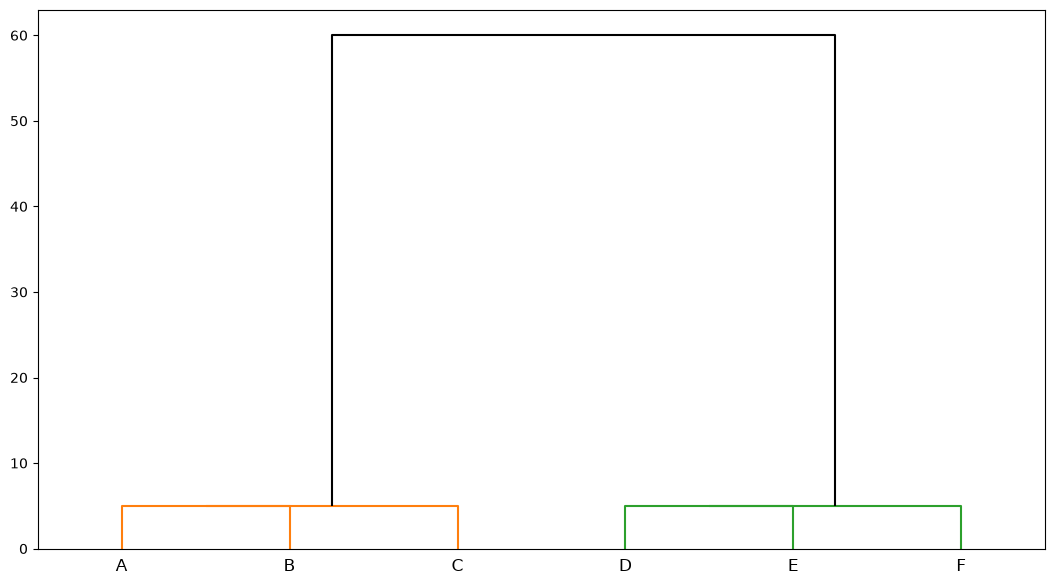

In [9]:
plt.figure(figsize=(13, 7))

dendrogram(
    Z,
    labels=students,
    color_threshold=20,
    above_threshold_color='black'
)

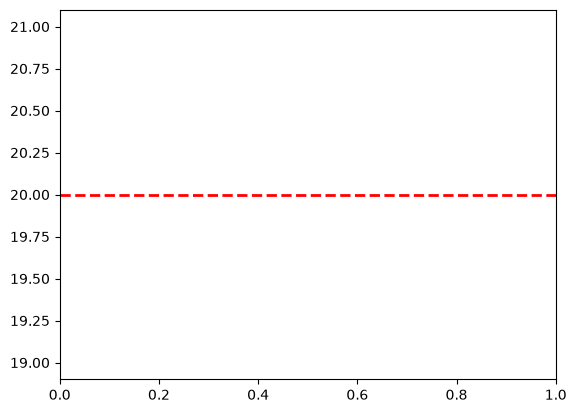

In [10]:
plt.axhline(
    y=20,
    color='red',
    linestyle='--',
    linewidth=2,
    label='Cut at Distance = 20'
)

Text(0.5, 1.0, 'Agglomerative Hierarchical Clustering - Dendrogram')

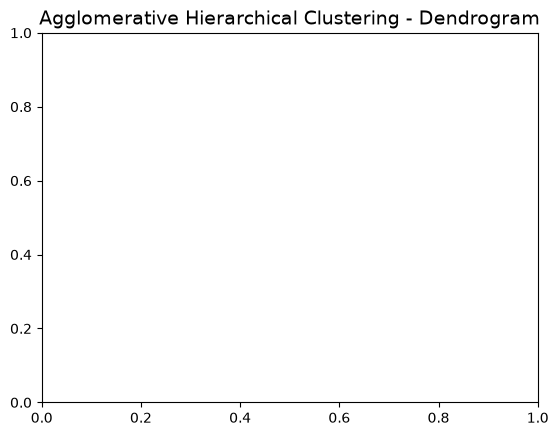

In [11]:
plt.title(
    'Agglomerative Hierarchical Clustering - Dendrogram',
    fontsize=14
)

Text(0, 0.5, 'Distance')

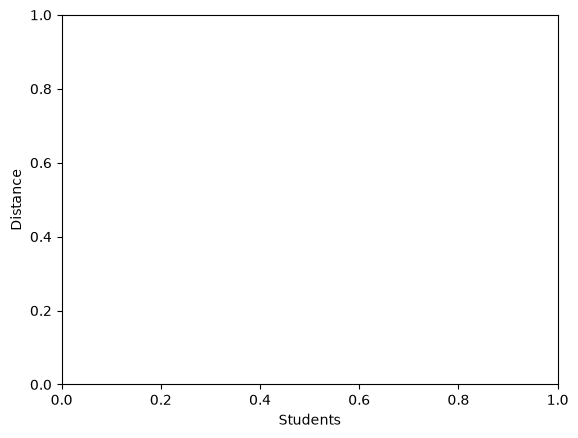

In [12]:
plt.xlabel("Students")
plt.ylabel("Distance")

C:\Users\Asus\AppData\Local\Temp\ipykernel_35452\19477683.py:1: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


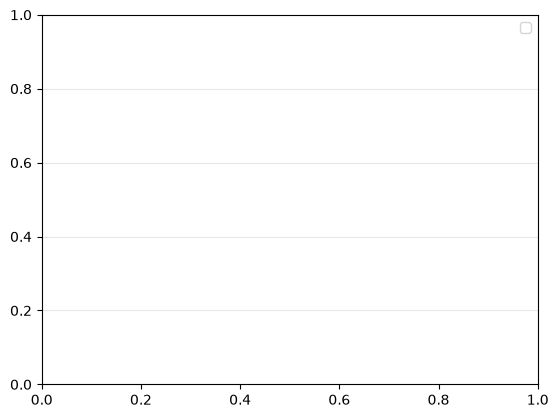

In [13]:
plt.legend()
plt.grid(axis='y', alpha=0.3)

In [14]:
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>